In [1]:
# Python 3.14.7
#* Imports
import numpy as np #2.5.3
import matplotlib.pyplot as plt #3.11.2
from scipy import stats #1.18.1
from scipy.optimize import minimize
from astropy.cosmology import LambdaCDM #8.0.2

#* Ploting style snippet for consistency.
plt.rcParams.update({
    "font.size": 18,
    "font.family": "serif",
    "figure.autolayout": True,
    "axes.grid": False,
    # "xtick.minor.visible": True,
    # "ytick.minor.visible": True,
})



### Activity 1: Central Limit Theorem

<>:36: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:38: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:36: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:38: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\bleicester\AppData\Local\Temp\ipykernel_8208\1462507062.py:36: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax[ind].set(xlabel="$\mu$")
C:\Users\bleicester\AppData\Local\Temp\ipykernel_8208\1462507062.py:38: SyntaxWarning: "\m" is an invalid escape sequence. Such sequenc

array([[<Axes: ylabel='$P(\\mu)$'>, <Axes: >, <Axes: >],
       [<Axes: xlabel='$\\mu$', ylabel='$P(\\mu)$'>,
        <Axes: xlabel='$\\mu$'>, <Axes: xlabel='$\\mu$'>]], dtype=object)

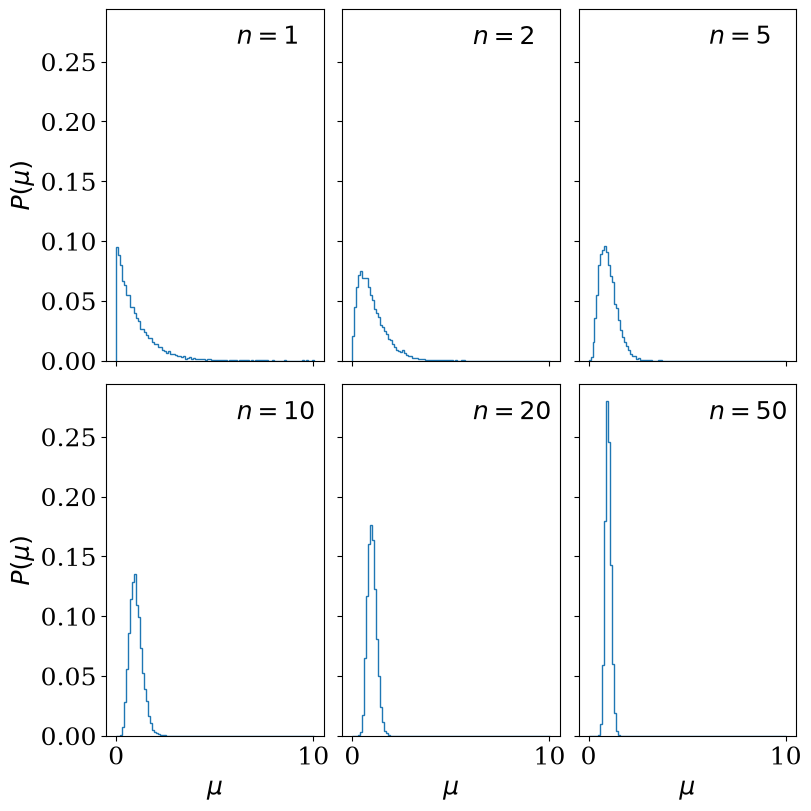

In [2]:
def s_draw():
    rng = np.random.default_rng()

    return - np.log(rng.random())

m=10000


fig,ax = plt.subplots(2,3, figsize=(8,8), layout="constrained", sharex=True, sharey=True)

ax = np.ravel(ax)

for ind, n in enumerate([1,2,5,10,20,50]):
    mus = []

    for j in range(m):
        draws = []
        for i in range(n):
            draws.append(s_draw())

        mu = np.mean(draws)
        mus.append(mu)

    if ind == 0:
        bins = np.linspace(0,np.max(mus),101) #* Same bins for each run, from largest spread of values

    hist,_ = np.histogram(mus, bins)

    hist = hist/ np.sum(hist)

    # print(np.sum(hist)) #* == 1 to float precision

    ax[ind].stairs(hist, bins)

    if ind >2:
        ax[ind].set(xlabel="$\mu$")
    if ind%3==0:
        ax[ind].set(ylabel="$P(\mu)$")
    
    ax[ind].text(0.6, 0.9, f"$n={n}$", transform=ax[ind].transAxes)


ax.reshape(2,3)

I Think fixing the $x$ and $y$ lims to be the same in each panel helps show how the distributions change with $n$ 

### Activity 2: Neutron Star Masses

For the NS datasets, the t statistic for sets sharing a mean is -3.1064, with significance 0.0028
The KS test has a statistic d=0.6150, with significance 0.000076


<>:17: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:21: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:17: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:21: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
C:\Users\bleicester\AppData\Local\Temp\ipykernel_8208\3233034505.py:17: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax[0].axvline(doub_ns.mean(), c="k", ls="--", label="$\mu$")
C:\Users\bleicester\AppData\Local\Temp\ipykernel_8208\3233034505.py:21: SyntaxWarning: "\o" is an inva

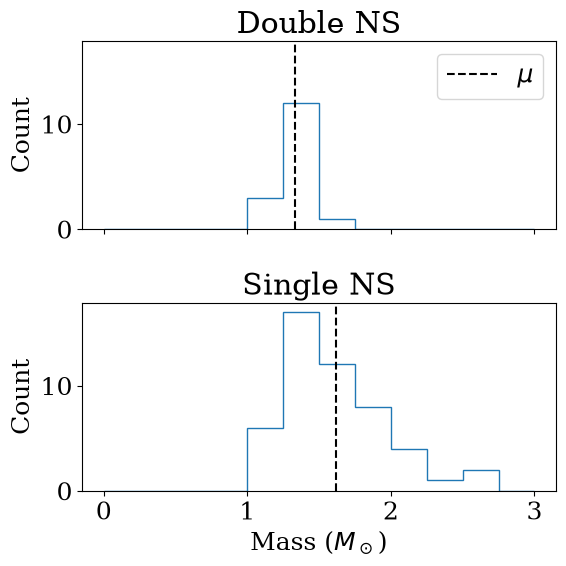

In [3]:
doub_ns = np.loadtxt("../Datasets/ns_masses1.dat")

sing_ns = np.loadtxt("../Datasets/ns_masses2.dat")

ns_means_t, ns_means_p = stats.ttest_ind(doub_ns, sing_ns)
print(f"For the NS datasets, the t statistic for sets sharing a mean is {ns_means_t:.4f}, with significance {ns_means_p:.4f}")

ns_ks_d, ns_ks_p = stats.ks_2samp(doub_ns, sing_ns)
print(f"The KS test has a statistic d={ns_ks_d:.4f}, with significance {ns_ks_p:.6f}")


fig, ax  = plt.subplots(2,figsize=(6,6), sharex=True, sharey=True)

bins = np.linspace(0,3,13)

ax[0].stairs(*np.histogram(doub_ns,bins))
ax[0].axvline(doub_ns.mean(), c="k", ls="--", label="$\mu$")
ax[0].set(title="Double NS", ylabel="Count")
ax[1].stairs(*np.histogram(sing_ns,bins))
ax[1].axvline(sing_ns.mean(), c="k", ls="--")
ax[1].set(title="Single NS", xlabel = "Mass ($M_\odot$)",ylabel="Count")

ax[0].legend()

### Activity 3

[Text(0.5, 0, '$z$'), Text(0, 0.5, '$DM$')]

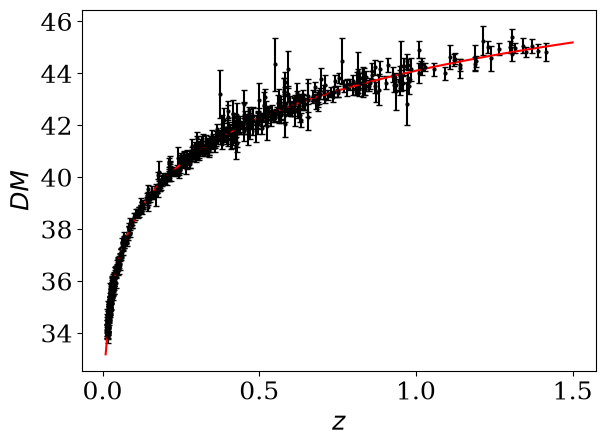

In [4]:

# * Stolen setup code from Class notebook 

# Function which determines the supernova luminosity distance for given cosmological parameters (Omega_m, Omega_L)
def getdmmod(p,z):
  om,ol = p[0],p[1]
  cosmo = LambdaCDM(H0=70.,Om0=om,Ode0=ol)
  r = cosmo.comoving_distance(z).value
  dl = r*(1.+z)
  return 5.*np.log10(dl) + 25.

# Read in and plot the supernova dataset
# You will need to change the file path to the location where you've saved the data
datfile = '../datasets/SN_dataset.dat'
data = np.loadtxt(datfile)
z,dm,dmerr = data[:,0],data[:,1],data[:,2]


#! I dislike this plotting style
# plt.plot(z,dm,marker='o',markersize=2,color='black',linestyle='None')
# plt.errorbar(z,dm,yerr=dmerr,color='black',capsize=2.,linestyle='None')
# # Overplot a standard cosmological model as an example
# xmin,xmax = 0.,1.5
# zmod = np.linspace(0.01,xmax,100)
# p = [0.3,0.7] # values of (Omega_m, Omega_L)
# dmmod = getdmmod(p,zmod)
# plt.plot(zmod,dmmod,color='red')
# plt.xlabel(r'$z$')
# plt.ylabel(r'$DM$')

#* So reseting

#* basic 70, 0.3, 0.7 model
xmin,xmax = 0.,1.5
zmod = np.linspace(0.01,xmax,100)
p = [0.3,0.7] # values of (Omega_m, Omega_L)
dmmod = getdmmod(p,zmod)

#* Plotting seperately
fig, ax = plt.subplots()
ax.errorbar(z,dm,yerr=dmerr,marker='o',markersize=2,
             color='black',capsize=2.,linestyle='None')
ax.plot(zmod,dmmod,color='red')# Overplot a standard cosmological model as an example
ax.set(xlabel= r'$z$', ylabel=r'$DM$')

In [ ]:
def chisqForCosmoModel(p,z,dm,dmerr):
    modVals = getdmmod(p, z)
    chisq = np.sum(((dm - modVals)/(dmerr))**2) #sum(((x-mu)/sig)^2)
    return chisq

def sumToOneCon(x):
    """Flat cosmology has the sum of Omega's == 1"""
    return np.sum(x)-1



#* Setup 
minOm, maxOm, nOm = 0,1,100
minOl, maxOl, nOl = 0,1,100
dOm = (maxOm-minOm)/nOm
dOl = (maxOl-minOl)/nOl
dof = len(z)-2

#* Using minimize
res = minimize(chisqForCosmoModel, [0.3,0.7], (z,dm,dmerr), bounds=[[minOm,maxOm],[minOl,maxOl]], 
                # constraints={"type":"eq", "fun":sumToOneCon} #! does change res, but only changes chi2 by 7e-4 
                #? Does this decrease DOF???
               )
best_omega_m_minimize, best_omega_l_minimize = res["x"]
min_chisq_cosmo = res["fun"]

print(f"The best fitting parameters from the minimize routine are (Omega_m, Omega_l) = ({best_omega_m_minimize:.3f}, {best_omega_l_minimize:.3f}) \nwith a chi^2 = {min_chisq_cosmo:.5f} and {dof} dof, for a reduced chi^2 of {(min_chisq_cosmo/dof):.3f}")
print("")

#* Using Grid
omega_m_grid = np.linspace(minOm+0.5*dOm, maxOm-0.5*dOm, nOm)
omega_l_grid = np.linspace(minOl+0.5*dOl, maxOl-0.5*dOl, nOl)


chisq_cosmo_grid = np.empty([nOm, nOl])
paramsSum = np.empty_like(chisq_cosmo_grid)

#! Double for loop takes a while for large number of datapoints
for i in range(nOm):
    for j in range(nOl):
        paramsSum[i,j] = omega_m_grid[i] + omega_l_grid[j]
        chisq_cosmo_grid[i,j] = chisqForCosmoModel([omega_m_grid[i], omega_l_grid[j]],z,dm,dmerr)


min_chisq_cosmo_grid = chisq_cosmo_grid.min()

iBest, jBest = np.unravel_index(chisq_cosmo_grid.argmin(), chisq_cosmo_grid.shape)

grid_best_Omega_m = omega_m_grid[iBest]
grid_best_Omega_l = omega_l_grid[jBest]

print(f"The best fitting parameters from the grid search are (Omega_m, Omega_l) = ({grid_best_Omega_m:.3f}, {grid_best_Omega_l:.3f}) \nwith a chi^2 = {min_chisq_cosmo_grid:.5f} and {dof} dof, for a reduced chi^2 of {(min_chisq_cosmo_grid/dof):.3f}")
print("")

clst = np.array([0.,2.30,6.17,11.8])  #// ! need to update for ~580 dof
#* NO need to update, as it relies on the number of parameters, not the number of dof. 
clst += min_chisq_cosmo_grid

oneSigDchisq = 1 # // !to change from table
#* Also no need to change, as it is just the parameters numbers that are changing, not the total dof. 
chisqCutVal = min_chisq_cosmo_grid+oneSigDchisq



omega_m_min_chisq = chisq_cosmo_grid.min(axis=1) #* marginlise over #omega_l, taking the smallest chisq for each omega_m grid point 
minPoint_omega_m = omega_m_min_chisq.argmin()

#* Error taken from closest datapoint, not an interpolation. If higher accuracy is wanted, increase number of gridpoints
upI_omega_m = np.abs(chisqCutVal-omega_m_min_chisq[minPoint_omega_m:]).argmin() #! how much further along to go 
downI_omega_m = np.abs(chisqCutVal-omega_m_min_chisq[:minPoint_omega_m]).argmin() #! how far from the start to go 

lower_omega_m = omega_m_grid[downI_omega_m]
upper_omega_m = omega_m_grid[minPoint_omega_m+upI_omega_m]

err_omega_m = (upper_omega_m-lower_omega_m) / 2

print(f"The 68% confidence interval for Omega_m is {lower_omega_m} -> {upper_omega_m}")
print(f"The Omega_m from a grid search is {grid_best_Omega_m:.3f} ± {err_omega_m:.3f}")
print("")


#! Duplicated for omega_l

omega_l_min_chisq = chisq_cosmo_grid.min(axis=0) #
minPoint_omega_l = omega_l_min_chisq.argmin()

upI_omega_l = np.abs(chisqCutVal-omega_l_min_chisq[minPoint_omega_l:]).argmin() #* how much further along to go 
downI_omega_l = np.abs(chisqCutVal-omega_l_min_chisq[:minPoint_omega_l]).argmin() #* how far from the start to go 

lower_omega_l = omega_l_grid[downI_omega_l]
upper_omega_l = omega_l_grid[minPoint_omega_l+upI_omega_l]

err_omega_l = (upper_omega_l-lower_omega_l) / 2

print(f"The 68% confidence interval for Omega_l is {lower_omega_l} -> {upper_omega_l}")
print(f"The Omega_l from a grid search is {grid_best_Omega_l:.3f} ± {err_omega_l:.3f}")

The best fitting parameters are (Omega_m, Omega_l) = (0.281, 0.725) 
with a chi^2 = 562.22619 and 578 dof, for a reduced chi^2 of 0.973
The best fitting parameters from the grid search are (Omega_m, Omega_l) = (0.295, 0.735) 
with a chi^2 = 562.23602 and 578 dof, for a reduced chi^2 of 0.973

The 68% confidence interval for Omega_m is 0.125 -> 0.455
The Omega_m from a grid search is 0.295 ± 0.165

The 68% confidence interval for Omega_l is 0.595 -> 0.865
The Omega_l from a grid search is 0.735 ± 0.135


C:\Users\bleicester\AppData\Local\Temp\ipykernel_8208\1893159271.py:11: UserWarning: Legend does not support handles for QuadContourSet instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(fontsize=10)


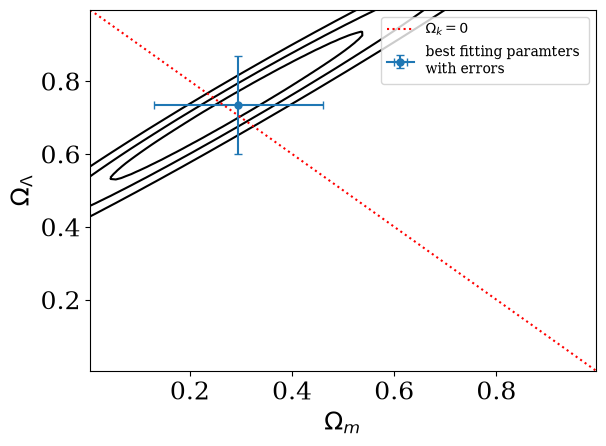

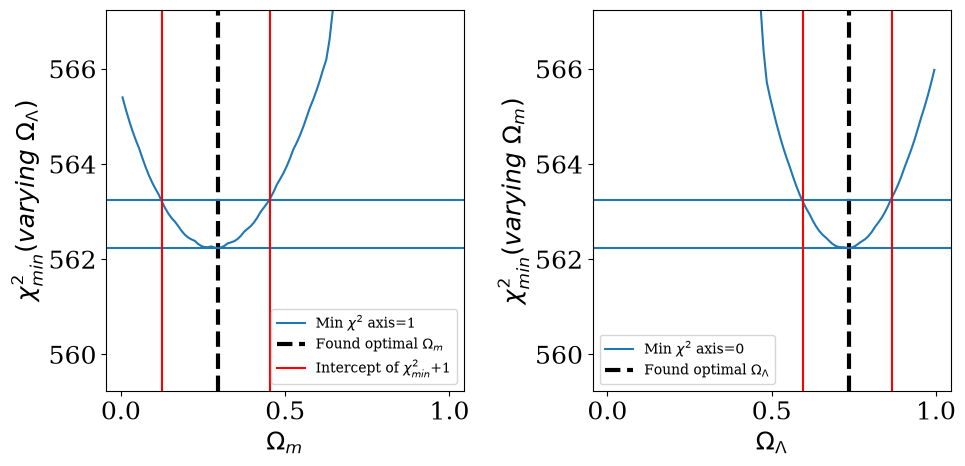

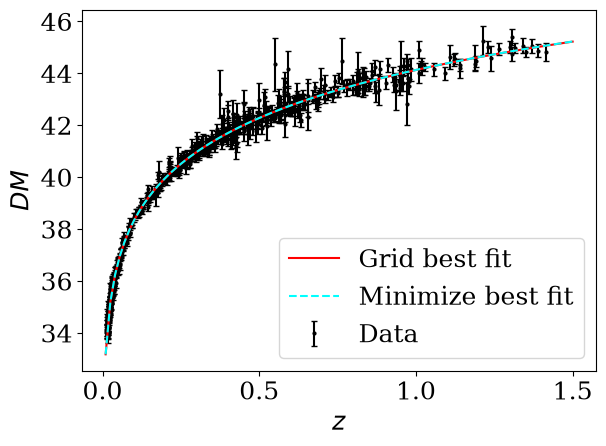

In [9]:
fig, ax =plt.subplots()

ax.contour(*np.meshgrid(omega_m_grid, omega_l_grid, indexing="ij"), chisq_cosmo_grid, levels=clst, colors="k", label="contours")
# ax.scatter(grid_best_Omega_m, grid_best_Omega_l, c="k", label="best fitting paramters")

ax.errorbar(grid_best_Omega_m, grid_best_Omega_l, xerr=err_omega_m, yerr=err_omega_l,  c="tab:blue", capsize=3, marker="o", markersize=5,label="best fitting paramters \nwith errors")

ax.plot(omega_m_grid, 1-omega_m_grid, label=r"$\Omega_k=0$", c="red", ls=":")

ax.set(xlabel=r"$\Omega_m$", ylabel=r"$\Omega_\Lambda$")
ax.legend(fontsize=10)



fig2, ax2 = plt.subplots(1,2, figsize=(10,5), sharex=True)

ax2[0].plot(omega_m_grid, omega_m_min_chisq, label=r"Min $\chi^2$ axis=1")
ax2[0].axvline(grid_best_Omega_m, c="k", lw=3,ls="--", label=r"Found optimal $\Omega_m$")
# ax2[0].axvline(omega_m_grid[minPoint_omega_m])
ax2[0].axhline(chisqCutVal)
ax2[0].axhline(min_chisq_cosmo_grid)
ax2[0].axvline(upper_omega_m, c="red", label=rf"Intercept of $\chi^2_{{min}}$+{oneSigDchisq}")
ax2[0].axvline(lower_omega_m, c="red")
ax2[0].set(xlabel=r"$\Omega_m$", ylabel=rf"$\chi^2_{{min}} (varying \ \Omega_\Lambda)$", ylim=(min_chisq_cosmo_grid-3,  min_chisq_cosmo_grid+5))
ax2[0].legend(fontsize=10)


ax2[1].plot(omega_l_grid, omega_l_min_chisq, label=r"Min $\chi^2$ axis=0")
ax2[1].axvline(grid_best_Omega_l, c="k", lw=3,ls="--", label=r"Found optimal $\Omega_\Lambda$")
# ax2[1].axvline(omega_l_grid[minPoint_omega_l])

ax2[1].axhline(chisqCutVal)
ax2[1].axhline(min_chisq_cosmo_grid)

ax2[1].axvline(upper_omega_l, c="red")
ax2[1].axvline(lower_omega_l, c="red")

ax2[1].set(xlabel=r"$\Omega_\Lambda$",ylabel=fr"$\chi^2_{{min}} (varying \ \Omega_m)$", ylim=(min_chisq_cosmo_grid-3,  min_chisq_cosmo_grid+5))
ax2[1].legend(fontsize=10)


fig3, ax3, = plt.subplots()

ax3.errorbar(z,dm,yerr=dmerr,marker='o',markersize=2,
             color='black',capsize=2.,linestyle='None', label="Data")
ax3.plot(zmod,getdmmod([grid_best_Omega_m,grid_best_Omega_l],zmod),color='red', label="Grid best fit", zorder=10)# Overplot best from grid

ax3.plot(zmod,getdmmod([best_omega_m_minimize,best_omega_l_minimize],zmod),color='cyan', ls="--", label="Minimize best fit", zorder=15)# Overplot best from minimize

ax3.set(xlabel= r'$z$', ylabel=r'$DM$')
ax3.legend()